# Coeliac mutagenesis analysis

In this notebook we try to recreate the results of the paper that the α1 peptide is a stronger binder than the ω1 peptide and that disrupting the 'WD' motif in the CDR3β will reduce binding to both epitopes.

In [1]:
import re

import anarci
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
SIGNIFICANCE_LEVEL = 0.05

In [3]:
sequences = pd.read_csv('../data/interim/sequences_coeliac_mutations.csv', index_col='id')

In [4]:
sequences['wd_motif'] = sequences['cdr3_beta'].map(
    lambda cdr3_beta: 'Contains WD motif' if 'WD' in cdr3_beta else 'Does not contain WD motif'
)

In [5]:
sequences['original'] = sequences.index.map(lambda id_: 'original' in id_)

cdr3_alpha = sequences[sequences['original']]['cdr3_alpha'].unique()[0]
sequences_beta_only_mutations = sequences[sequences['cdr3_alpha'] == cdr3_alpha].copy()

In [6]:
def find_mutation_location(new_chain: str, original: str) -> tuple[int, str]:
    numbering, _ = anarci.number(new_chain)

    original_idx = 0
    for (seq_id, insert_code), residue in numbering:
        if residue == '-':
            continue

        if residue != original[original_idx]:
            return seq_id, insert_code

        original_idx += 1

    msg = f'No mutation found in {new_chain}'
    raise ValueError(msg)


sequences_beta_only_mutations[['mutation_seq_id', 'mutation_insert_code_id']] = None

sequences_beta_only_mutations.loc[
    (sequences_beta_only_mutations['pmhc_calls'] == 'a1') & ~sequences_beta_only_mutations['original'],
    ['mutation_seq_id', 'mutation_insert_code_id'],
] = (
    sequences_beta_only_mutations.loc[
        (sequences_beta_only_mutations['pmhc_calls'] == 'a1') & ~sequences_beta_only_mutations['original'],
        'tcr_beta_chain',
    ]
    .map(
        lambda tcr_beta_chain: find_mutation_location(
            tcr_beta_chain, sequences_beta_only_mutations.loc['coeliac_a1_mut_original', 'tcr_beta_chain']
        )
    )
    .apply(pd.Series)
    .to_numpy()
)

sequences_beta_only_mutations.loc[
    (sequences_beta_only_mutations['pmhc_calls'] == 'w1') & ~sequences_beta_only_mutations['original'],
    ['mutation_seq_id', 'mutation_insert_code_id'],
] = (
    sequences_beta_only_mutations.loc[
        (sequences_beta_only_mutations['pmhc_calls'] == 'w1') & ~sequences_beta_only_mutations['original'],
        'tcr_beta_chain',
    ]
    .map(
        lambda tcr_beta_chain: find_mutation_location(
            tcr_beta_chain, sequences_beta_only_mutations.loc['coeliac_w1_mut_original', 'tcr_beta_chain']
        )
    )
    .apply(pd.Series)
    .to_numpy()
)

In [7]:
true_structural_features = pd.read_csv('../data/processed/coeliac_structure_structural_features.csv')
true_sc_and_bsa = pd.read_csv('../data/processed/coeliac_structure_sc_and_bsa.csv')

true_structural_features = true_structural_features.merge(true_sc_and_bsa)

true_structural_features['antigen'] = true_structural_features['name'].map(
    lambda name: re.match(r'DQ2_5([a-z]\d)_572G2_DECAB', name).group(1)
)

In [8]:
def process_contacts(contacts: pd.DataFrame, group_name: str | list[str]) -> pd.DataFrame:
    contact_antigens = contacts[contacts['chain_type_pmhc'] == 'antigen_chain'].copy()
    contact_antigens['relative_pos_centre_pmhc'] = contact_antigens['relative_pos_centre_pmhc'].astype(int)

    contact_antigens_scores = (
        contact_antigens.groupby(group_name)
        .value_counts(['cdr_type', 'relative_pos_centre_tcr', 'relative_pos_centre_pmhc'])
        .reset_index()
        .pivot_table(
            index=group_name,
            columns=['cdr_type', 'relative_pos_centre_tcr', 'relative_pos_centre_pmhc'],
            values='count',
        )
        .fillna(0)
        .map(int)
    )
    contact_antigens_scores.columns = [
        '_'.join(str(idx) for idx in indices) for indices in contact_antigens_scores.columns.to_flat_index()
    ]

    contacts_mhc = contacts[contacts['chain_type_pmhc'].isin({'mhc_chain1', 'mhc_chain2'})].copy()
    contacts_mhc_scores = (
        contacts_mhc.groupby(group_name)
        .value_counts(['cdr_type', 'relative_pos_centre_tcr', 'chain_type_pmhc', 'resi_pmhc'])
        .reset_index()
        .pivot_table(
            index=group_name,
            columns=['cdr_type', 'relative_pos_centre_tcr', 'chain_type_pmhc', 'resi_pmhc'],
            values='count',
        )
        .fillna(0)
        .map(int)
    )

    contacts_mhc_scores.columns = [
        '_'.join(str(idx) for idx in indices) for indices in contacts_mhc_scores.columns.to_flat_index()
    ]

    contacts_scores = pd.concat([contact_antigens_scores, contacts_mhc_scores], axis=1).fillna(0).map(int)
    contacts_scores = contacts_scores.reset_index()

    return contacts_scores

In [9]:
true_contact_maps = pd.read_csv('../data/processed/coeliac_structure_contacts.csv')

true_contact_maps['relative_pos_centre_tcr'] = true_contact_maps['relative_pos_centre_tcr'].astype(int)
true_contact_maps['resi_pmhc'] = true_contact_maps['resi_pmhc'].astype(str).str.replace('.0', '')

true_contact_maps_scores = process_contacts(true_contact_maps, 'name')

true_contact_maps_scores['antigen'] = true_contact_maps_scores['name'].map(
    lambda name: re.match(r'DQ2_5([a-z]\d)_572G2_DECAB', name).group(1)
)

In [10]:
true_interactions = pd.read_csv('../data/processed/coeliac_structure_interactions.csv')

In [11]:
true_a1_interactions_summary = (
    true_interactions.query("name == 'DQ2_5a1_572G2_DECAB'")[
        ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue', 'distance']
    ]
    .sort_values('original_numbering')
    .reset_index(drop=True)
)
true_a1_interactions_summary['ligand_number'] = true_a1_interactions_summary['ligand_number'] + 1

true_w1_interactions_summary = (
    true_interactions.query("name == 'DQ2_5w1_572G2_DECAB'")[
        ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue', 'distance']
    ]
    .sort_values(['original_numbering', 'ligand_number'])
    .reset_index(drop=True)
)
true_w1_interactions_summary['ligand_number'] = true_w1_interactions_summary['ligand_number'] + 1

In [12]:
sequences_beta_only_mutations['disrupts_interaction'] = None

sequences_beta_only_mutations.loc[sequences_beta_only_mutations['pmhc_calls'] == 'a1', 'disrupts_interaction'] = (
    sequences_beta_only_mutations.loc[sequences_beta_only_mutations['pmhc_calls'] == 'a1', 'mutation_seq_id'].map(
        lambda mutation_seq_id: mutation_seq_id in true_a1_interactions_summary['original_numbering'].tolist()
    )
)
sequences_beta_only_mutations.loc[sequences_beta_only_mutations['pmhc_calls'] == 'w1', 'disrupts_interaction'] = (
    sequences_beta_only_mutations.loc[sequences_beta_only_mutations['pmhc_calls'] == 'w1', 'mutation_seq_id'].map(
        lambda mutation_seq_id: mutation_seq_id in true_w1_interactions_summary['original_numbering'].tolist()
    )
)
sequences_beta_only_mutations['disrupts_interaction'] = sequences_beta_only_mutations['disrupts_interaction'].astype(
    bool
)

In [13]:
confidence_scores = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_coeliac_mutations.csv')

In [14]:
confidence_scores = confidence_scores.merge(
    sequences_beta_only_mutations, how='inner', left_on='name', right_index=True
)

In [15]:
binding_scores = pd.read_csv('../data/processed/af3_af3_tcrmodel2_coeliac_mutations_pae_aggregator_predictions.csv')
binding_scores['prediction'] = binding_scores[
    ['prediction_1', 'prediction_2', 'prediction_3', 'prediction_4', 'prediction_5']
].apply('median', axis=1)

In [16]:
binding_scores = binding_scores.merge(sequences_beta_only_mutations, how='inner', left_on='name', right_index=True)

## Structure prediction quality

In [17]:
CAPRI_ACCEPTABLE_CUTOFF = 0.23
CAPRI_MEDIUM_CUTOFF = 0.49
CAPRI_HIGH_CUTOFF = 0.80

In [18]:
dockq_scores = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_dockq_coeliac.csv')
dockq_scores[['name', 'reference_structure']] = dockq_scores['name'].str.split('-').apply(pd.Series)

In [19]:
dockq_scores = dockq_scores.merge(confidence_scores, how='inner', on=['name', 'seed', 'sample']).merge(
    binding_scores[['name', 'seed', 'sample', 'prediction']], how='inner', on=['name', 'seed', 'sample']
)

In [20]:
dockq_scores['top_rank'] = False
dockq_scores.loc[dockq_scores.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

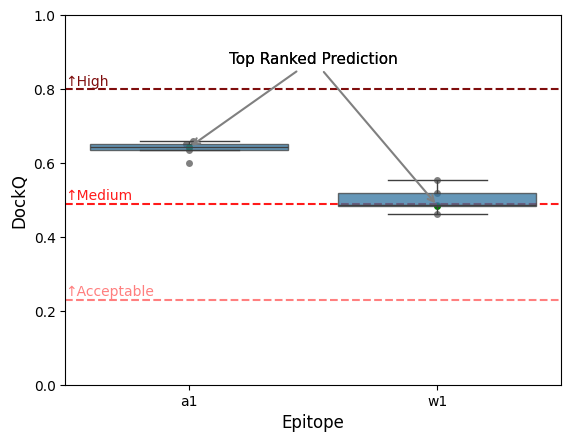

In [21]:
fig, ax = plt.subplots(1, 1)

for label, cutoff, colour in (
    ('↑Acceptable', CAPRI_ACCEPTABLE_CUTOFF, '#ff7f7f'),
    ('↑Medium', CAPRI_MEDIUM_CUTOFF, '#ff1a1a'),
    ('↑High', CAPRI_HIGH_CUTOFF, '#7f0d0d'),
):
    ax.text(-0.5, cutoff + 0.01, label, color=colour)
    ax.axhline(cutoff, linestyle='dashed', color=colour)

sns.boxplot(
    dockq_scores,
    x='pmhc_calls',
    y='DockQ',
    color='tab:blue',
    showfliers=False,
    boxprops={'alpha': 0.75},
    zorder=2,
    ax=ax,
)
sns.swarmplot(dockq_scores.query('not top_rank'), y='DockQ', x='pmhc_calls', color='grey', zorder=1, ax=ax)
sns.swarmplot(dockq_scores.query('top_rank'), y='DockQ', x='pmhc_calls', color='green', zorder=1, ax=ax)

for _, pmhc_calls, dockq in dockq_scores.query('top_rank')[['pmhc_calls', 'DockQ']].itertuples():
    ax.annotate(
        'Top Ranked Prediction',
        xy=(pmhc_calls, dockq),
        xycoords='data',
        xytext=(0.50, 0.90),
        textcoords='axes fraction',
        va='top',
        ha='center',
        arrowprops={'arrowstyle': '->', 'color': 'gray', 'lw': 1.5},
        fontsize=11,
    )

ax.set_ylim([0.0, 1.0])

ax.set_ylabel(ax.get_ylabel(), fontsize=12)
ax.set_xlabel('Epitope', fontsize=12)

plt.savefig('../report/figures/coeliac_tcrs_dockq.svg')
plt.show()

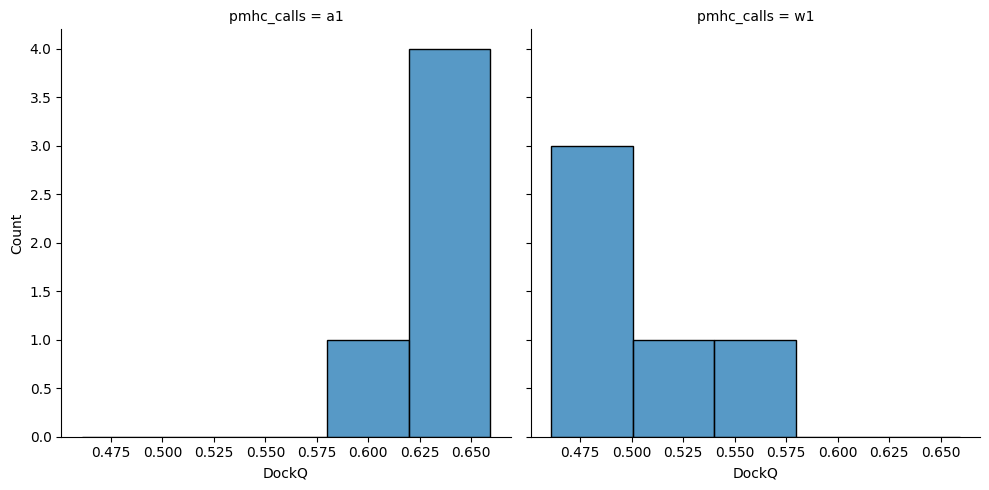

In [22]:
sns.displot(dockq_scores, col='pmhc_calls', x='DockQ', kind='hist')
plt.show()

In [23]:
pg.mwu(
    dockq_scores[dockq_scores['pmhc_calls'] == 'a1']['DockQ'],
    dockq_scores[dockq_scores['pmhc_calls'] == 'w1']['DockQ'],
    alternative='two-sided',
)

,U-val,alternative,p-val,RBC,CLES
MWU,25.0,two-sided,0.007937,1.0,1.0


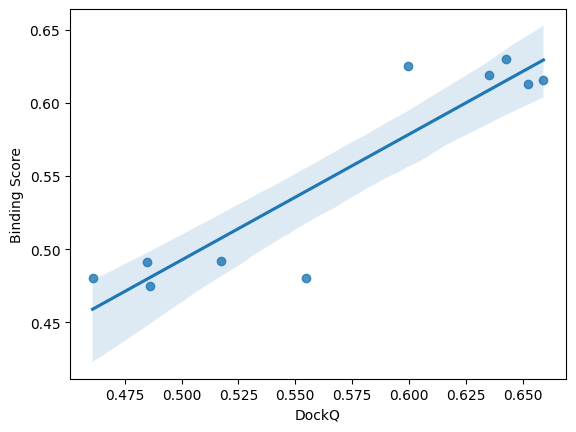

In [24]:
ax = sns.regplot(dockq_scores, x='DockQ', y='prediction')

ax.set_xlabel('DockQ')
ax.set_ylabel('Binding Score')

plt.savefig('../report/figures/coeliac_corr_confidence_dockq.svg')
plt.show()

In [25]:
result = pg.corr(dockq_scores['DockQ'], dockq_scores['prediction'], alternative='less')

print(f"R^2 = {result.iloc[0]['r'] ** 2:.2f}")
result

R^2 = 0.85


,n,r,CI95%,p-val,BF10,power
pearson,10,0.92138,"[-1.0, 0.98]",0.999924,0.121,1.003683e-09


## Epitope baseline binding score

In [26]:
binding_scores.value_counts(['pmhc_calls', 'wd_motif']).sort_index()

pmhc_calls  wd_motif                 
a1          Contains WD motif            35
            Does not contain WD motif    10
w1          Contains WD motif            35
            Does not contain WD motif    10
Name: count, dtype: int64

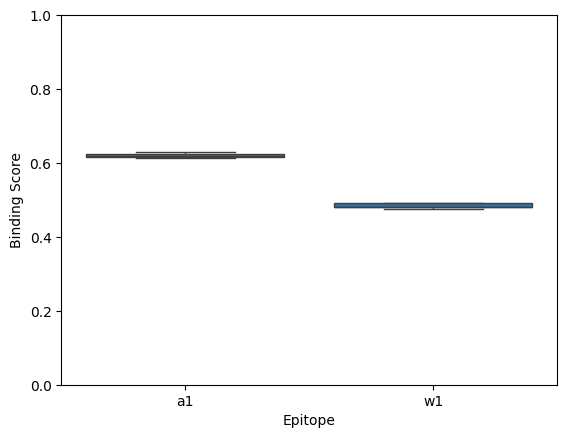

In [27]:
ax = sns.boxplot(binding_scores.query('original'), x='pmhc_calls', y='prediction')

ax.set_xlabel('Epitope')
ax.set_ylabel('Binding Score')
ax.set_ylim([0.0, 1.0])

plt.savefig('../report/figures/coeliac_epitope_affinity_boxplot.svg')
plt.show()

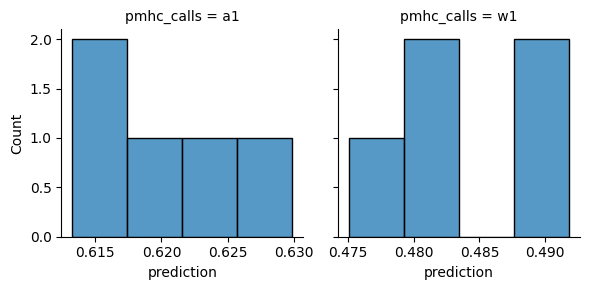

In [28]:
grid = sns.FacetGrid(binding_scores.query('original'), col='pmhc_calls', sharex=False)
grid.map_dataframe(sns.histplot, x='prediction')

plt.show()

In [29]:
result = pg.mwu(
    binding_scores.query("original and pmhc_calls == 'a1'")['prediction'],
    binding_scores.query("original and pmhc_calls == 'w1'")['prediction'],
    alternative='greater',
)
result['significant'] = result['p-val'] < SIGNIFICANCE_LEVEL

result

,U-val,alternative,p-val,RBC,CLES,significant
MWU,25.0,greater,0.003968,1.0,1.0,True


## Mutagenesis analysis

In [30]:
binding_scores_mutations = binding_scores.query('not original')

### WD-motif

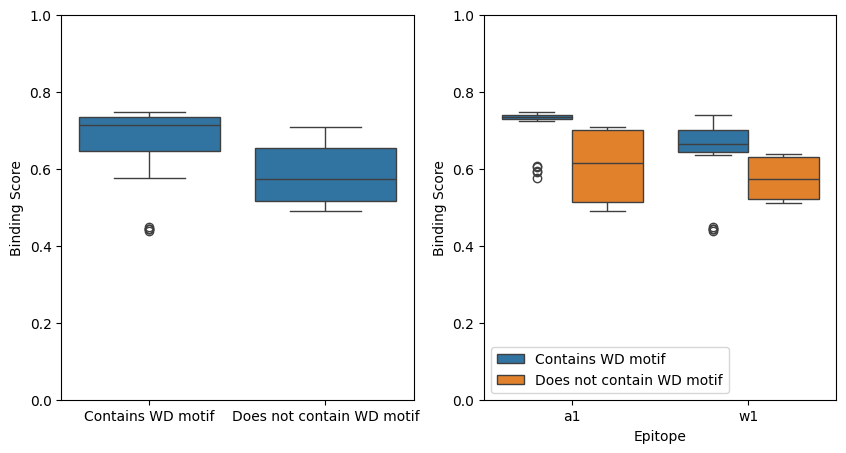

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.boxplot(binding_scores_mutations, x='wd_motif', y='prediction', ax=axes[0])

axes[0].set_ylabel('Binding Score')
axes[0].set_xlabel('')
axes[0].set_ylim(0.0, 1.0)

sns.boxplot(binding_scores_mutations, x='pmhc_calls', y='prediction', hue='wd_motif', ax=axes[1])

axes[1].set_ylabel('Binding Score')
axes[1].set_xlabel('Epitope')
axes[1].set_ylim(0.0, 1.0)

axes[1].legend(title='', loc='lower left')

plt.savefig('../report/figures/coeliac_mutations_boxplot.svg')
plt.show()

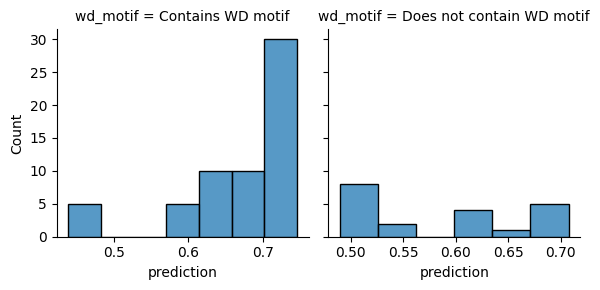

In [32]:
grid = sns.FacetGrid(binding_scores_mutations, col='wd_motif', sharex=False)
grid.map_dataframe(sns.histplot, x='prediction')

plt.show()

In [33]:
result = pg.mwu(
    binding_scores_mutations.query("wd_motif == 'Contains WD motif'")['prediction'],
    binding_scores_mutations.query("wd_motif == 'Does not contain WD motif'")['prediction'],
    alternative='greater',
)
result['significant'] = result['p-val'] < SIGNIFICANCE_LEVEL

result

,U-val,alternative,p-val,RBC,CLES,significant
MWU,958.0,greater,0.000036,0.596667,0.798333,True


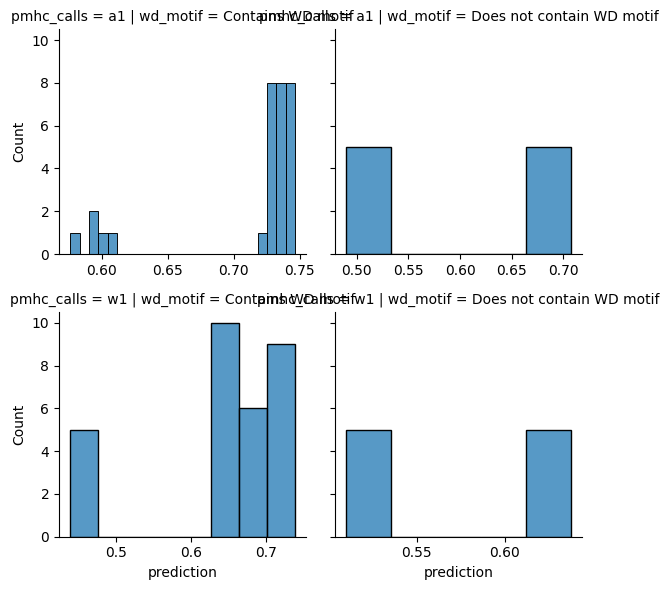

In [34]:
grid = sns.FacetGrid(binding_scores_mutations, row='pmhc_calls', col='wd_motif', sharex=False)
grid.map_dataframe(sns.histplot, x='prediction')

plt.show()

In [35]:
result = pg.anova(binding_scores_mutations, dv='prediction', between=['pmhc_calls', 'wd_motif'])
result['significant'] = result['p-unc'] < SIGNIFICANCE_LEVEL

result

,Source,SS,DF,MS,F,p-unc,np2,significant
0,pmhc_calls,0.075449,1.0,0.075449,12.154463,0.000817,0.137877,True
1,wd_motif,0.111341,1.0,0.111341,17.936659,0.000063,0.190944,True
2,pmhc_calls * wd_motif,0.005927,1.0,0.005927,0.954751,0.331613,0.012407,False
3,Residual,0.471768,76.0,0.006207,NaN,NaN,NaN,False


In [36]:
results = []

for pmhc_calls, epitope_group in binding_scores_mutations.groupby('pmhc_calls'):
    result = pg.ttest(
        epitope_group.query("wd_motif == 'Contains WD motif'")['prediction'],
        epitope_group.query("wd_motif == 'Does not contain WD motif'")['prediction'],
        alternative='greater',
    )
    result['epitope_name'] = pmhc_calls

    results.append(result)

results = pd.concat(results)
results = results.set_index('epitope_name')
results['significant'] = results['p-val'] < (SIGNIFICANCE_LEVEL / len(results))

results

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power,significant
epitope_name,,,,,,,,,
a1,3.131482,10.710363,greater,0.004924,"[0.05, inf]",1.545878,22.949,0.993993,True
w1,2.625269,25.978752,greater,0.007158,"[0.02, inf]",0.754806,8.459,0.649972,True


### All interactions

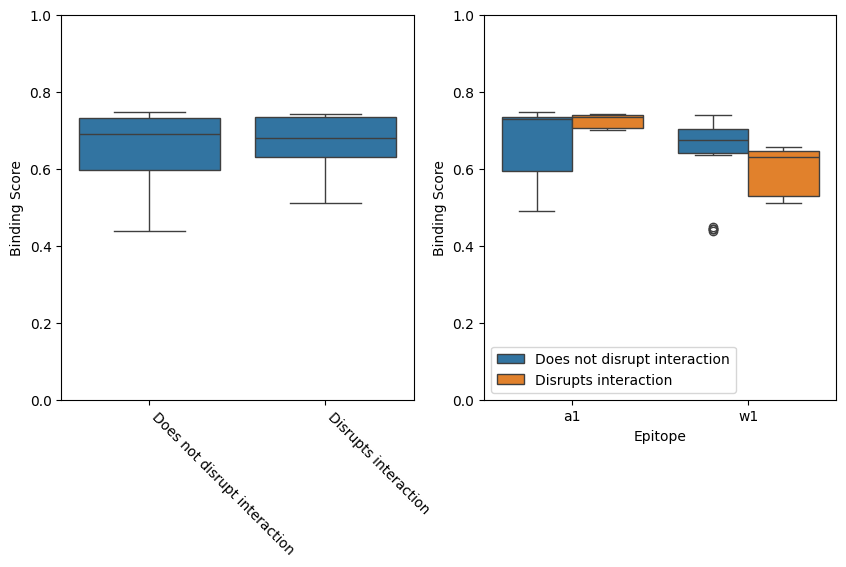

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.boxplot(binding_scores_mutations, x='disrupts_interaction', y='prediction', ax=axes[0])

axes[0].set_ylabel('Binding Score')
axes[0].set_ylim(0.0, 1.0)

axes[0].set_xlabel('')
axes[0].set_xticks(axes[0].get_xticks())
axes[0].set_xticklabels(
    [
        {'True': 'Disrupts interaction', 'False': 'Does not disrupt interaction'}[label.get_text()]
        for label in axes[0].get_xticklabels()
    ],
    rotation=-45,
    ha='left',
)

sns.boxplot(binding_scores_mutations, x='pmhc_calls', y='prediction', hue='disrupts_interaction', ax=axes[1])

axes[1].set_ylabel('Binding Score')
axes[1].set_ylim(0.0, 1.0)

axes[1].set_xlabel('Epitope')

handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(
    handles,
    [{'True': 'Disrupts interaction', 'False': 'Does not disrupt interaction'}[label] for label in labels],
    title='',
    loc='lower left',
)

plt.savefig('../report/figures/coeliac_interaction_mutations_boxplot.svg')
plt.show()

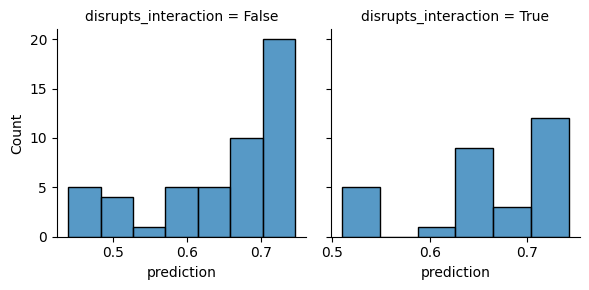

In [38]:
grid = sns.FacetGrid(binding_scores_mutations, col='disrupts_interaction', sharex=False)
grid.map_dataframe(sns.histplot, x='prediction')

plt.show()

In [39]:
result = pg.mwu(
    binding_scores_mutations.loc[~binding_scores_mutations['disrupts_interaction'], 'prediction'],
    binding_scores_mutations.loc[binding_scores_mutations['disrupts_interaction'], 'prediction'],
    alternative='greater',
)
result['significant'] = result['p-val'] < SIGNIFICANCE_LEVEL

result

,U-val,alternative,p-val,RBC,CLES,significant
MWU,703.0,greater,0.681558,-0.062667,0.468667,False


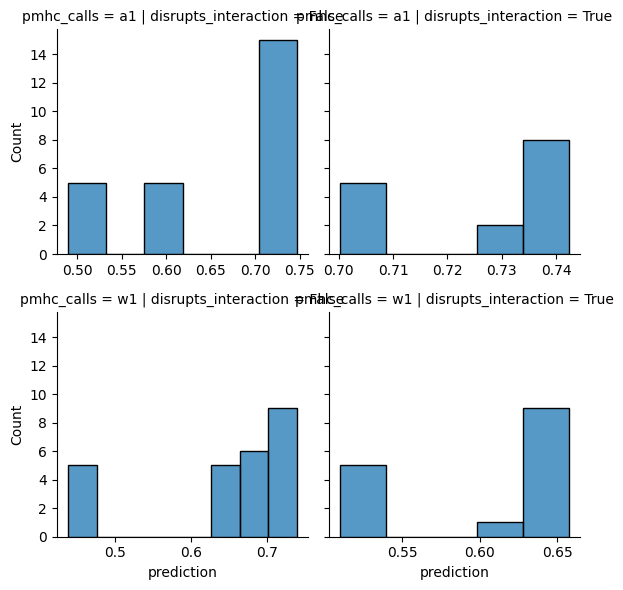

In [40]:
grid = sns.FacetGrid(binding_scores_mutations, row='pmhc_calls', col='disrupts_interaction', sharex=False)
grid.map_dataframe(sns.histplot, x='prediction')

plt.show()

In [41]:
result = pg.anova(binding_scores_mutations, dv='prediction', between=['pmhc_calls', 'disrupts_interaction'])
result['significant'] = result['p-unc'] < SIGNIFICANCE_LEVEL

result

,Source,SS,DF,MS,F,p-unc,np2,significant
0,pmhc_calls,0.075449,1.0,0.075449,10.709175,0.001605,0.123507,True
1,disrupts_interaction,0.003008,1.0,0.003008,0.427026,0.515424,0.005587,False
2,pmhc_calls * disrupts_interaction,0.050591,1.0,0.050591,7.180843,0.009030,0.086328,True
3,Residual,0.535437,76.0,0.007045,NaN,NaN,NaN,False


In [42]:
results = []

for pmhc_calls, epitope_group in binding_scores_mutations.groupby('pmhc_calls'):
    result = pg.ttest(
        epitope_group.query('not disrupts_interaction')['prediction'],
        epitope_group.query('disrupts_interaction')['prediction'],
        alternative='greater',
    )
    result['epitope_name'] = pmhc_calls

    results.append(result)

results = pd.concat(results)
results = results.set_index('epitope_name')
results['significant'] = results['p-val'] < (SIGNIFICANCE_LEVEL / len(results))

results

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power,significant
epitope_name,,,,,,,,,
a1,-3.287661,26.547213,greater,0.998577,"[-0.1, inf]",0.841607,0.03,0.000015,False
w1,1.515615,37.940044,greater,0.068952,"[-0.0, inf]",0.433828,1.545,0.366854,False


## Correlation between confidence score and SPR

In [43]:
affinities = {
    'coeliac_a1_mut_original': 6.1,
    'coeliac_a1_mut_10': 8.2,
    'coeliac_a1_mut_14': np.inf,
    'coeliac_a1_mut_15': 280,
    'coeliac_w1_mut_original': 37.8,
    'coeliac_w1_mut_10': 41.2,
    'coeliac_w1_mut_14': np.inf,
    'coeliac_w1_mut_15': np.inf,
}
binding_scores['affinity'] = binding_scores['name'].map(affinities)

Scaling affinity by $$\frac{x_{min}}{x}$$

In [44]:
binding_scores['affinity_norm'] = binding_scores['affinity'].min() / binding_scores['affinity']

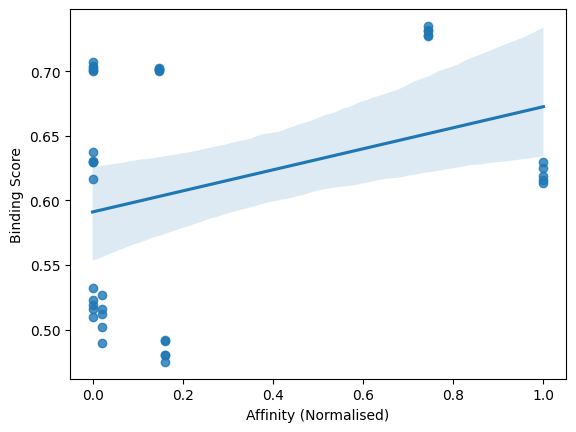

In [45]:
ax = sns.regplot(binding_scores, x='affinity_norm', y='prediction')

ax.set_xlabel('Affinity (Normalised)')
ax.set_ylabel('Binding Score')

plt.savefig('../report/figures/coeliac_mutations_corr_affinity_confidence.svg')
plt.show()

In [46]:
result = pg.corr(binding_scores['affinity_norm'], binding_scores['prediction'], alternative='greater')

print(f"R^2 = {result.iloc[0]['r'] ** 2:.2f}")
result

R^2 = 0.11


,n,r,CI95%,p-val,BF10,power
pearson,40,0.325862,"[0.07, 1.0]",0.020086,2.937,0.66967


## Structure overlap

### Structural Features

In [47]:
predicted_structural_features = pd.read_csv(
    '../data/processed/predicted_af3_af3_tcrmodel2_structural_features_coeliac_mutations.csv'
)
predicted_structural_features = predicted_structural_features.merge(
    sequences_beta_only_mutations, how='right', left_on='name', right_index=True
)

predicted_sc_and_bsa = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_sc_and_bsa_coeliac_mutations.csv')

predicted_structural_features = predicted_structural_features.merge(
    predicted_sc_and_bsa, on=['name', 'seed', 'sample'], how='left'
)

In [48]:
value_columns = [
    col for col in predicted_structural_features.select_dtypes('number').columns if col not in ('seed', 'sample')
]

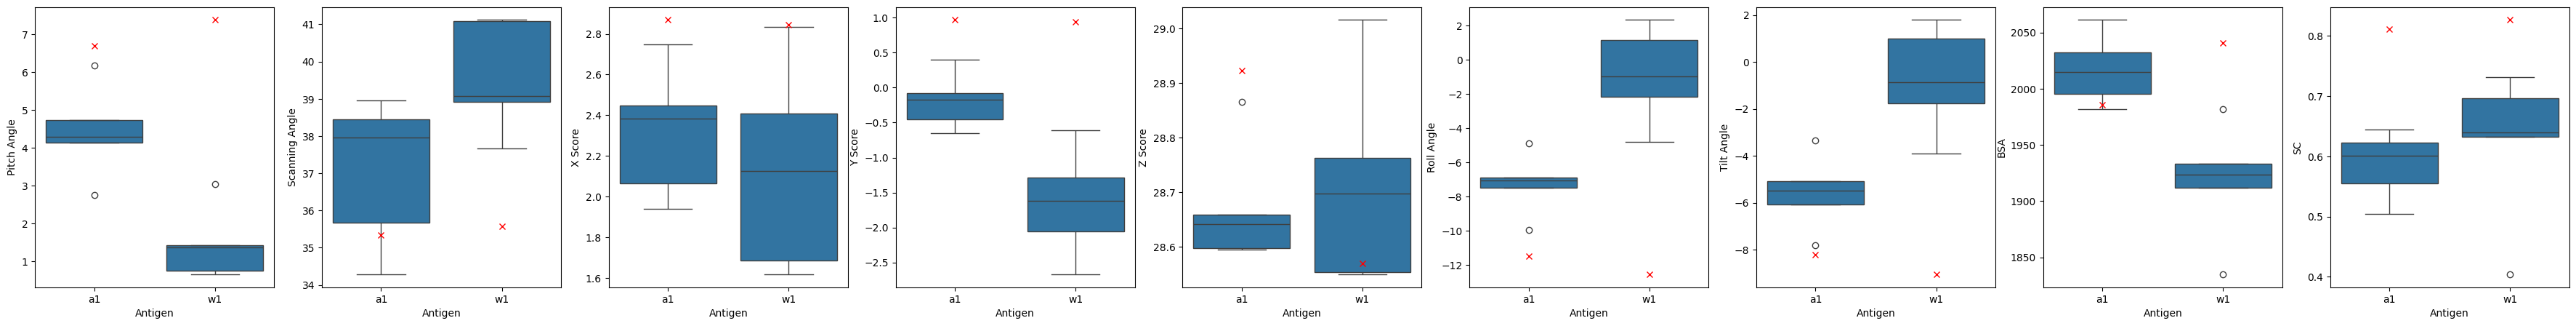

In [49]:
fig, axes = plt.subplots(1, len(value_columns), figsize=(5 * len(value_columns), 5))
for column_name, ax in zip(value_columns, axes, strict=True):
    sns.boxplot(
        predicted_structural_features[predicted_structural_features['original']], y=column_name, x='pmhc_calls', ax=ax
    )

    old_label = ax.get_ylabel()

    ax.set_ylabel(old_label.replace('_', ' ').title() if len(old_label.split('_')) > 1 else old_label.upper())
    ax.set_xlabel('Antigen')

    for i, antigen in enumerate(label.get_text() for label in ax.get_xticklabels()):
        true_value = true_structural_features.loc[true_structural_features['antigen'] == antigen, column_name].iloc[0]
        ax.plot(i, true_value, 'rx')

In [50]:
antigens = true_structural_features['antigen'].unique()

print('True value in predicted 95% CI?\n')
print(f"                       {'        '.join(antigens)}")

for column_name in value_columns:
    print(f'{column_name:<20}', end='')
    for antigen in antigens:
        predicted_values = predicted_structural_features.loc[
            predicted_structural_features['original'] & (predicted_structural_features['pmhc_calls'] == antigen),
            column_name,
        ]
        true_value = true_structural_features.loc[true_structural_features['antigen'] == antigen, column_name].iloc[0]

        predicted_values_mean = predicted_values.mean()
        predicted_values_sem = predicted_values.sem()

        print(
            (
                (predicted_values_mean - predicted_values_sem)
                <= true_value
                <= (predicted_values_mean + predicted_values_sem)
            ),
            end='     ',
        )

    print()

True value in predicted 95% CI?

                       a1        w1
pitch_angle         False     False     
scanning_angle      False     False     
x_score             False     False     
y_score             False     False     
z_score             False     False     
roll_angle          False     False     
tilt_angle          False     False     
bsa                 False     False     
sc                  False     False     


### Contact Maps

In [51]:
predicted_contact_maps = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_contact_maps_coeliac_mutations.csv')

predicted_contact_maps['relative_pos_centre_tcr'] = predicted_contact_maps['relative_pos_centre_tcr'].astype(int)
predicted_contact_maps['resi_pmhc'] = predicted_contact_maps['resi_pmhc'].astype(str).str.replace('.0', '')

predicted_contact_maps_scores = process_contacts(predicted_contact_maps, ['name', 'seed', 'sample'])

predicted_contact_maps_scores = predicted_contact_maps_scores.merge(
    sequences_beta_only_mutations, how='right', left_on='name', right_index=True
)

In [52]:
true_contact_names = set(true_contact_maps_scores.select_dtypes('number').columns)
predicted_contact_names = {
    column_name
    for column_name in predicted_contact_maps_scores.select_dtypes('number').columns
    if column_name not in ('seed', 'sample')
}

for column_name in predicted_contact_names - true_contact_names:
    true_contact_maps_scores[column_name] = 0

for column_name in true_contact_names - predicted_contact_names:
    predicted_contact_maps_scores[column_name] = 0

In [53]:
contact_names = sorted(true_contact_names | predicted_contact_names)

In [54]:
antigens = sorted(true_contact_maps_scores['antigen'].unique())
similarities = {}
for antigen in antigens:
    predicted_contact_maps_scores_values = predicted_contact_maps_scores.loc[
        predicted_contact_maps_scores['original'] & (predicted_contact_maps_scores['pmhc_calls'] == antigen),
        contact_names,
    ].to_numpy()
    true_contact_maps_scores_values = true_contact_maps_scores.loc[
        true_contact_maps_scores['antigen'] == antigen, contact_names
    ].to_numpy()

    between = cosine_similarity(predicted_contact_maps_scores_values, true_contact_maps_scores_values)
    between = between.flatten()

    within = cosine_similarity(predicted_contact_maps_scores_values, predicted_contact_maps_scores_values)
    within = np.array([within[i, j] for i in range(len(within)) for j in range(i + 1, len(within))])

    similarities[antigen] = {
        'between': between.tolist(),
        'within': within.tolist(),
    }

similarities = pd.DataFrame(similarities)
similarities.index.name = 'comparison'
similarities = (
    similarities.explode(antigens)
    .reset_index()
    .melt(id_vars='comparison', value_vars=antigens, var_name='antigen', value_name='cosine_similarity')
)
similarities['cosine_similarity'] = similarities['cosine_similarity'].astype(float)

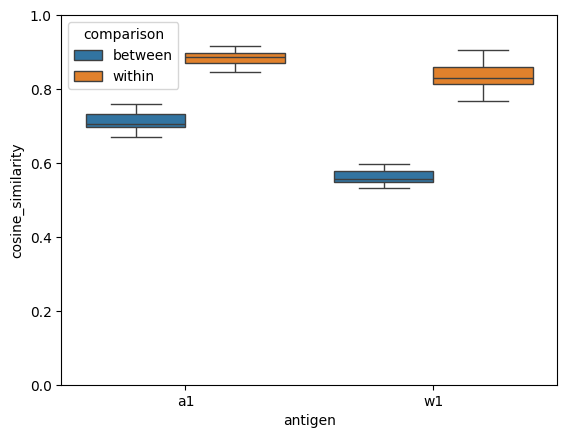

In [55]:
ax = sns.boxplot(similarities, x='antigen', y='cosine_similarity', hue='comparison')
ax.set_ylim(0, 1)

plt.show()

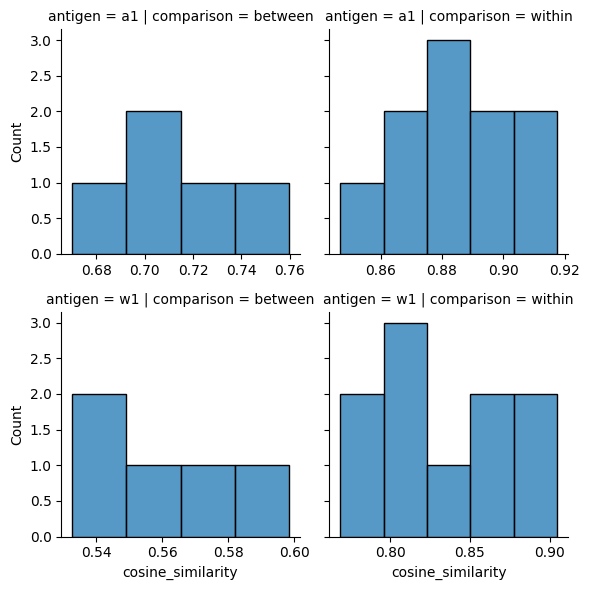

In [56]:
grid = sns.FacetGrid(similarities, row='antigen', col='comparison', sharex=False)
grid.map_dataframe(sns.histplot, x='cosine_similarity')

plt.show()

In [57]:
result = pg.anova(similarities, dv='cosine_similarity', between=['antigen', 'comparison'])
result['significant'] = result['p-unc'] < SIGNIFICANCE_LEVEL

result

,Source,SS,DF,MS,F,p-unc,np2,significant
0,antigen,0.053317,1.0,0.053317,45.923569,3.424675e-07,0.638505,True
1,comparison,0.329973,1.0,0.329973,284.215939,1.625167e-15,0.916187,True
2,antigen * comparison,0.016180,1.0,0.016180,13.936159,9.340248e-04,0.348961,True
3,Residual,0.030186,26.0,0.001161,NaN,NaN,NaN,False


In [58]:
results = []

for antigen, epitope_group in similarities.groupby('antigen'):
    result = pg.ttest(
        epitope_group.query("comparison == 'within'")['cosine_similarity'],
        epitope_group.query("comparison == 'between'")['cosine_similarity'],
    )
    result['antigen'] = antigen

    results.append(result)

results = pd.concat(results)
results = results.set_index('antigen')
results['significant'] = results['p-val'] < (SIGNIFICANCE_LEVEL / len(results))

results

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power,significant
antigen,,,,,,,,,
a1,10.272507,5.776496,two-sided,6.310135e-05,"[0.13, 0.21]",6.513638,5.628e+04,1.0,True
w1,14.790922,12.528573,two-sided,2.644994e-09,"[0.23, 0.31]",6.762245,2.943e+06,1.0,True


### Interactions

In [59]:
predicted_interactions = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_interactions_coeliac_mutations.csv')
predicted_interactions = predicted_interactions.merge(
    sequences_beta_only_mutations, how='right', left_on='name', right_index=True
)

In [60]:
def calculate_interaction_accuracy(group: pd.DataFrame, true_interactions: pd.DataFrame) -> tuple[float, float]:
    group = group.merge(
        true_interactions[
            ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue']
        ],
        how='outer',
        indicator=True,
    )
    classification = group['_merge'].map({'both': 'TP', 'left_only': 'FP', 'right_only': 'FN'})
    classification_counts = classification.value_counts()

    return (
        (classification_counts['TP'] / classification_counts.sum()) * 100,
        (classification_counts['FP'] / classification_counts.sum()) * 100,
    )

#### α1 epitope

In [61]:
true_a1_interactions_summary

,type,domain,original_numbering,protein_residue,ligand_number,ligand_residue,distance
0,hydrophobic,VB,37,ARG,9,PRO,3.612334
1,hydrophobic,VB,108,LEU,9,PRO,3.775657
2,hydrophobic,VB,109,VAL,9,PRO,3.919943
3,hydrophobic,VB,112,TRP,6,PRO,3.813673


In [62]:
original_a1_interactions = predicted_interactions.query("original and pmhc_calls == 'a1'")

num_predictions = len(original_a1_interactions.drop_duplicates(['name', 'seed', 'sample']))

original_a1_interactions_summary = original_a1_interactions.value_counts(
    ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue']
)
original_a1_interactions_summary = (original_a1_interactions_summary / num_predictions) * 100
original_a1_interactions_summary.name = 'captured_percent'

original_a1_interactions_summary = original_a1_interactions_summary.reset_index()
original_a1_interactions_summary = original_a1_interactions_summary.sort_values('original_numbering')

original_a1_interactions_summary = original_a1_interactions_summary.merge(
    true_a1_interactions_summary[
        ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue']
    ],
    how='outer',
    indicator=True,
)
original_a1_interactions_summary['captured_percent'] = original_a1_interactions_summary['captured_percent'].fillna(0.0)

merge_mask = original_a1_interactions_summary['_merge'].isin(('both', 'right_only'))
original_a1_interactions_summary = original_a1_interactions_summary.drop('_merge', axis='columns')

original_a1_interactions_summary.style.apply(
    lambda row, merge_mask=merge_mask: ['font-weight: bold'] * len(row) if merge_mask[row.name] else [''] * len(row),
    axis=1,
)

,type,domain,original_numbering,protein_residue,ligand_number,ligand_residue,captured_percent
0,hydrophobic,VB,37,ARG,9,PRO,0.000000
1,hydrophobic,VB,108,LEU,9,PRO,40.000000
2,hydrophobic,VB,109,VAL,9,PRO,100.000000
3,hydrophobic,VB,112,TRP,6,PRO,80.000000


In [63]:
a1_interactions_accuracy = (
    predicted_interactions.query("pmhc_calls == 'a1'")
    .groupby(['name', 'seed', 'sample', 'original', 'wd_motif'])
    .apply(calculate_interaction_accuracy, true_interactions=true_a1_interactions_summary, include_groups=False)
    .apply(pd.Series)
)
a1_interactions_accuracy.columns = ['accuracy', 'noise']
a1_interactions_accuracy = a1_interactions_accuracy.reset_index()

In [64]:
a1_interactions_accuracy['status'] = None
a1_interactions_accuracy.loc[a1_interactions_accuracy['original'], 'status'] = 'Original'
a1_interactions_accuracy.loc[
    ~a1_interactions_accuracy['original'] & (a1_interactions_accuracy['wd_motif'] == 'Contains WD motif'), 'status'
] = 'Mutant (Contains WD motif)'
a1_interactions_accuracy.loc[
    ~a1_interactions_accuracy['original'] & (a1_interactions_accuracy['wd_motif'] == 'Does not contain WD motif'),
    'status',
] = 'Mutant (Does not contain WD motif)'

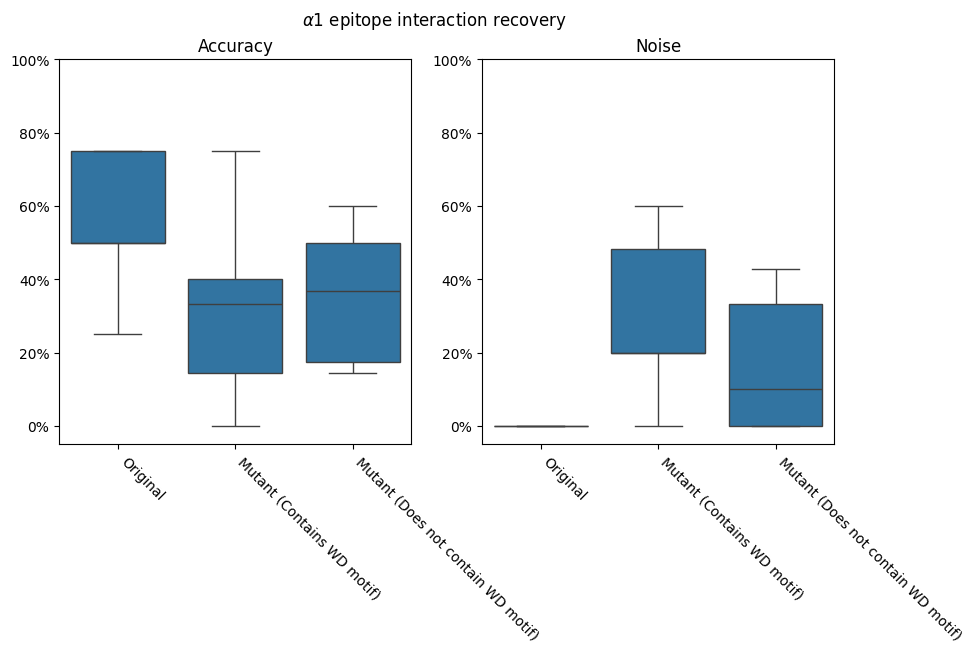

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

fig.suptitle(r'$\alpha$1 epitope interaction recovery')

sns.boxplot(
    a1_interactions_accuracy,
    x='status',
    y='accuracy',
    order=['Original', 'Mutant (Contains WD motif)', 'Mutant (Does not contain WD motif)'],
    ax=axes[0],
)

axes[0].set_title('Accuracy')
axes[0].set_ylabel('')
axes[0].set_ylim([-5, 100])
axes[0].yaxis.set_major_formatter(PercentFormatter())

axes[0].set_xlabel('')
axes[0].set_xticks(axes[0].get_xticks())
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=-45, ha='left')

sns.boxplot(
    a1_interactions_accuracy,
    x='status',
    y='noise',
    order=['Original', 'Mutant (Contains WD motif)', 'Mutant (Does not contain WD motif)'],
    ax=axes[1],
)
axes[1].set_title('Noise')
axes[1].set_ylabel('')
axes[1].set_ylim([-5, 100])
axes[1].yaxis.set_major_formatter(PercentFormatter())

axes[1].set_xlabel('')
axes[1].set_xticks(axes[0].get_xticks())
axes[1].set_xticklabels(axes[0].get_xticklabels(), rotation=-45, ha='left')

plt.savefig('../report/figures/coeliac_predicted_a1_interaction_recovery.svg')
plt.show()

#### ω1 epitope

In [66]:
true_w1_interactions_summary

,type,domain,original_numbering,protein_residue,ligand_number,ligand_residue,distance
0,hydrophobic,VB,108,LEU,9,PRO,3.565586
1,hydrophobic,VB,112,TRP,4,PRO,3.546830
2,hydrophobic,VB,112,TRP,6,PRO,3.620198
3,hydrophobic,VB,113,ASP,3,PHE,3.955730


In [67]:
original_w1_interactions = predicted_interactions.query("original and pmhc_calls == 'w1'")

num_predictions = len(original_w1_interactions.drop_duplicates(['name', 'seed', 'sample']))

original_w1_interactions_summary = original_w1_interactions.value_counts(
    ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue']
)
original_w1_interactions_summary = (original_w1_interactions_summary / num_predictions) * 100
original_w1_interactions_summary.name = 'captured_percent'

original_w1_interactions_summary = original_w1_interactions_summary.reset_index()
original_w1_interactions_summary = original_w1_interactions_summary.sort_values('original_numbering')

original_w1_interactions_summary = original_w1_interactions_summary.merge(
    true_w1_interactions_summary[
        ['type', 'domain', 'original_numbering', 'protein_residue', 'ligand_number', 'ligand_residue']
    ],
    how='outer',
    indicator=True,
)

original_w1_interactions_summary['captured_percent'] = original_w1_interactions_summary['captured_percent'].fillna(0.0)

merge_mask = original_w1_interactions_summary['_merge'].isin(('both', 'right_only'))
original_w1_interactions_summary = original_w1_interactions_summary.drop('_merge', axis='columns')

original_w1_interactions_summary.style.apply(
    lambda row, merge_mask=merge_mask: ['font-weight: bold'] * len(row) if merge_mask[row.name] else [''] * len(row),
    axis=1,
)

,type,domain,original_numbering,protein_residue,ligand_number,ligand_residue,captured_percent
0,hbond,VB,37,ARG,10,PHE,20.000000
1,hydrophobic,VB,108,LEU,9,PRO,0.000000
2,hydrophobic,VB,109,VAL,9,PRO,80.000000
3,hydrophobic,VB,112,TRP,4,PRO,0.000000
4,hydrophobic,VB,112,TRP,6,PRO,160.000000
5,hydrophobic,VB,113,ASP,3,PHE,0.000000


In [68]:
w1_interactions_accuracy = (
    predicted_interactions.query("pmhc_calls == 'w1'")
    .groupby(['name', 'seed', 'sample', 'original', 'wd_motif'])
    .apply(calculate_interaction_accuracy, true_interactions=true_a1_interactions_summary, include_groups=False)
    .apply(pd.Series)
)
w1_interactions_accuracy.columns = ['accuracy', 'noise']
w1_interactions_accuracy = a1_interactions_accuracy.reset_index()

In [69]:
w1_interactions_accuracy['status'] = None
w1_interactions_accuracy.loc[w1_interactions_accuracy['original'], 'status'] = 'Original'
w1_interactions_accuracy.loc[
    ~w1_interactions_accuracy['original'] & (w1_interactions_accuracy['wd_motif'] == 'Contains WD motif'), 'status'
] = 'Mutant (Contains WD motif)'
w1_interactions_accuracy.loc[
    ~w1_interactions_accuracy['original'] & (w1_interactions_accuracy['wd_motif'] == 'Does not contain WD motif'),
    'status',
] = 'Mutant (Does not contain WD motif)'

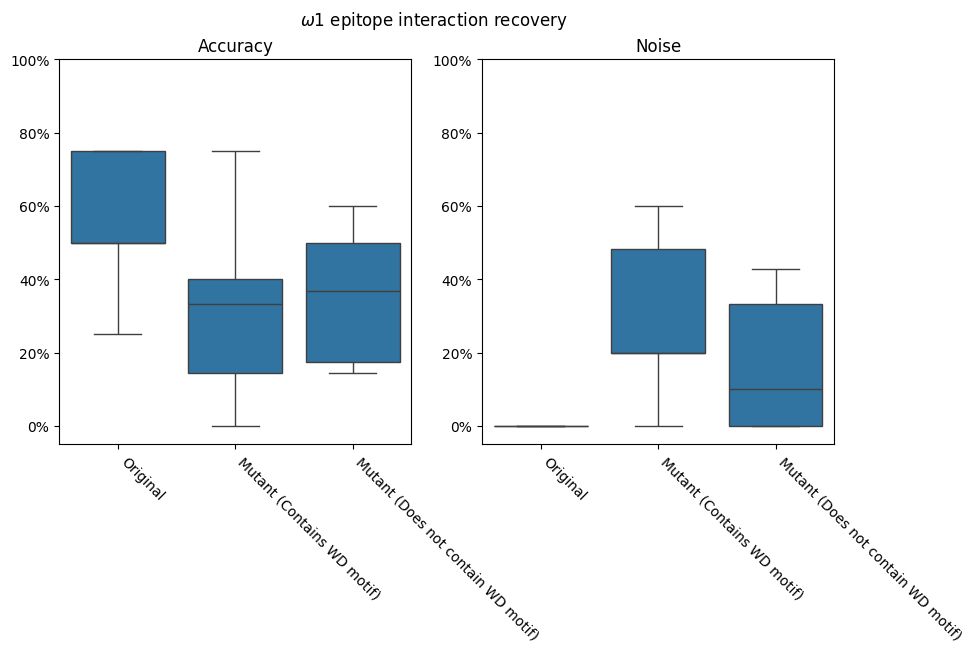

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

fig.suptitle(r'$\omega$1 epitope interaction recovery')

sns.boxplot(
    w1_interactions_accuracy,
    x='status',
    y='accuracy',
    order=['Original', 'Mutant (Contains WD motif)', 'Mutant (Does not contain WD motif)'],
    ax=axes[0],
)

axes[0].set_title('Accuracy')
axes[0].set_ylabel('')
axes[0].set_ylim([-5, 100])
axes[0].yaxis.set_major_formatter(PercentFormatter())

axes[0].set_xlabel('')
axes[0].set_xticks(axes[0].get_xticks())
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=-45, ha='left')

sns.boxplot(
    w1_interactions_accuracy,
    x='status',
    y='noise',
    order=['Original', 'Mutant (Contains WD motif)', 'Mutant (Does not contain WD motif)'],
    ax=axes[1],
)
axes[1].set_title('Noise')
axes[1].set_ylabel('')
axes[1].set_ylim([-5, 100])
axes[1].yaxis.set_major_formatter(PercentFormatter())

axes[1].set_xlabel('')
axes[1].set_xticks(axes[0].get_xticks())
axes[1].set_xticklabels(axes[0].get_xticklabels(), rotation=-45, ha='left')

plt.savefig('../report/figures/coeliac_predicted_w1_interaction_recovery.svg')
plt.show()